# Лабораторная работа №3

## Физика дела

Найти уровень энергии и волновую функцию $\psi(x)$ основного состояния в потенциальной яме $U(x)$, решая конечномерный аналог спектральной задачи для одномерного стационарного уранения Шрёдингера $$\begin{cases}(\hat{H} - E) \cdot \psi(x,t) = \left(-\frac{1}{2} \cdot \frac{\partial^2}{\partial x^2} + U(x) - E \right) \cdot \psi(x,t) = 0 \\ |\psi(x)| \rightarrow 0 \ , \ |x| \rightarrow \infty \end{cases}$$

Для поиска наименьшего собственного значения $E_0$ дискретной версии гамильтониана $\hat{H}$ (соответствующей ему трёхдиагональной матрицы) реализовать QR-алгоритм. 

Для этого сначала самостоятельно реализовать QR-разложение методом отражений, а затем сравнить его с QR-разложением из NumPy.  

Проверить работу программы, сравнив с точным решением для $U(x) = \frac{1}{2} x^2$.

Ладно, пока чет не очень понятно, че вообще нужно сделать... Попробую расписать это уравнение Шрёдингера.  

Я минут 10 посмотрел на это и понял.  

Во-первых $\hat{H}$ - это дифференциальный оператор (слово гамильтониан для непосвященных не сильно понятное), то есть $$\hat{H} = -\frac{1}{2} \cdot \frac{\partial^2}{\partial{x^2}} + U(x)$$

Разобрались. Дальше, очевидно, что: $$\left(-\frac{1}{2} \cdot \frac{\partial^2}{\partial{x^2}} + U(x) - E \right) \cdot \psi(x,t) = 0 \Longrightarrow -\frac{1}{2}\psi''(x,t) + U(x) \cdot \psi(x,t) - E \cdot \psi(x,t) = 0 \Longrightarrow$$

$$\Longrightarrow -\frac{1}{2}\psi''(x,t) + U(x) \cdot \psi(x,t) = E \cdot \psi(x,t) \Longrightarrow$$
$$\Longrightarrow \hat{H}\psi(x,t) = E\psi(x,t)$$

Ну и так как в задании буквально сказано, что уравнение **стационарное**, то не будем с собой дальше таскать эти $t$.

Соответственно.

Так как вторую производную можно представить в виде: $$\psi''(x_i) \approx \frac{\psi_{i-1} - 2\psi_i + \psi_{i+1}}{h^2})$$

Тогда $$-\frac{1}{2}\psi''(x) + U(x)\psi(x) = E \psi(x) \Longrightarrow -\frac{1}{2}\frac{\psi_{i-1} -2\psi_i + \psi_{i+1}}{h^2} + U(x_i)\psi_i = E\psi_i \Longrightarrow$$

$$\Longrightarrow -\frac{\psi_{i-1}}{2h^2} + \frac{\psi_i}{h^2} - \frac{\psi_{i+1}}{2h^2} + U(x_i)\psi_i = E\psi_i \Longrightarrow$$

$$\Longrightarrow -\frac{1}{2h^2}\psi_{i-1} + \left(\frac{1}{h^2} + U(x_i) \right)\cdot \psi_i - \frac{1}{2h^2}\psi_{i+1}=E\psi_i$$

Рассмотрим пример с маленьким отрезком (к примеру $[-2,2]$ и шагом $h=1$): $$\begin{cases} x_0 = -2, \\ x_1 = -1, \\ x_2 = 0, \\ x_3 = 1, \\ x_4 = 2 \end{cases}$$

Из-за условия на $\psi(x)$ имеем $$\begin{cases} \psi_0 = 0, \\ \psi_4 = 0 \end{cases}$$

Соответственно остаются неизвестными только $\psi_1, \psi_2, \psi_3$.

$$\begin{cases} -\frac{1}{2}\psi_{i-1} + \left(1 + U(x_i) \right)\psi_i - \frac{1}{2}\psi_{i+1} = E\psi_i \\ U(x) = \frac{x^2}{2} \end{cases} \Longrightarrow \begin{cases} U(-1) = 0.5 \\ U(0) = 0 \\ U(1) = 0.5 \end{cases} \Longrightarrow \begin{cases} 1.5\psi_1 - 0.5\psi_2 = E\psi_1 \\ -0.5\psi_1 + \psi_2 - 0.5\psi_3 = E\psi_2 \\ -0.5\psi_2 + 1.5\psi_3 = E\psi_3 \end{cases} \Longrightarrow$$

$$\Longrightarrow \begin{pmatrix}
1.5 & -0.5 & 0 \\ -0.5 & 1 & -0.5 \\ 0 & -0.5 & 1.5 \end{pmatrix} \cdot \begin{pmatrix} \psi_1 \\ \psi_2 \\ \psi_3 \end{pmatrix} = E \cdot \begin{pmatrix} \psi_1 \\ \psi_2 \\ \psi_3 \end{pmatrix} \equiv$$
$$\equiv H \cdot \psi =  E \cdot \psi \Longrightarrow$$
$$\Longrightarrow (H - E \cdot I)\psi = 0$$

Это однородная система линейных уравнений, она имеет решение, если $\det(H - E \cdot I) = 0 \Longrightarrow$

$$\Longrightarrow (0.5 - E)\cdot(1.5 - E)\cdot(2 - E) = 0 \Longrightarrow \begin{cases} E_0 = 0.5 \leftarrow \ минимальное \\ E_1 = 1.5 \\ E_2 = 2 \end{cases}$$

$E_0, E_1, E_2$ - собственные значения матрицы $H$. $E_0$ - минимальное. Попробуем найти собственный вектор $\psi$, который будет ему соответствовать.  

Пусть $\psi = \begin{pmatrix} 1 \\ 2 \\ 1 \end{pmatrix} \Longrightarrow$
$$\Longrightarrow H\psi = \begin{pmatrix} 1.5 & -0.5 & 0 \\ -0.5 & 1 & -0.5 \\ 0 & -0.5 & 1.5 \end{pmatrix} \cdot \begin{pmatrix} 1 \\ 2 \\ 1 \end{pmatrix} = \begin{pmatrix} 0.5 \\ 1 \\ 0.5 \end{pmatrix} \Longrightarrow H\psi = 0.5\psi \Longrightarrow H\psi = E_0\psi \Longrightarrow$$
Мы нашли пару $\begin{cases} E_0 = 0.5 \leftarrow \ собственное \ значение \\ \psi = \begin{pmatrix} 1 \\ 2 \\ 1 \end{pmatrix} \leftarrow \ собственный \ вектор \end{cases}$

В дальнейшем собственные значения матрицы $H$ будем находить с помощью $QR$-алгоритма, в основе которого лежит $QR$-разложение матрицы, которое реализуется методом отражений Хаусхолдера.



Для квадратной матрицы $A$ $QR$ разложение - это представление матрицы $A$ в виде: $$A = QR$$

Где $$\begin{cases} Q \ - \ ортогональная \ матрица \\ R \ - \ верхнетреугольниая \ матрица \end{cases} \Longleftrightarrow \begin{cases} Q^{T}Q=I \\ R = \begin{pmatrix} r_{11} & r_{12} & r_{13} \\ 0 & r_{22} & r_{23} \\ 0 & 0 & r_{33} \end{pmatrix} \end{cases}$$

## Метод отражений Хаусхолдера

Пусть $A = \begin{pmatrix} 3 & 1 \\ 4 & 2 \end{pmatrix}$, нам надо получить $R = \begin{pmatrix} * & * \\ 0 & * \end{pmatrix}$, то есть надо занулить число $4$.  

Рассмотрим столбец $x = \begin{pmatrix} 3 \\ 4 \end{pmatrix}$, его длина: $||X|| = \sqrt{3^2 + 4^2} = \sqrt{25} = 5$, тогда можно привести $x$ к вектору $y = \begin{pmatrix} -5 \\ 0 \end{pmatrix}$, сохранив длину $x$.  

Какое преобразование $u$ способно сделать $x \xrightarrow{u} y$?  

Предлагается вычислить следующий вектор: $$\bar{u} = \begin{cases} x + ||x||_2e_1, x_1 \geq 0 \\ x - ||x||_2e_1, x_1 < 0 \end{cases} \ , \ e_1 = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$$

В нашем случае $$x_1 = 3 > 0 \Longrightarrow \bar{u} = x + ||x||_2e_1 \Longrightarrow \bar{u} = \begin{pmatrix} 3 \\ 4 \end{pmatrix} + 5\begin{pmatrix} 1 \\ 0 \end{pmatrix} \Longrightarrow \bar{u} = \begin{pmatrix} 8 \\ 4 \end{pmatrix}$$

Заметим, что $$\bar{u} = x - y = \begin{pmatrix} 3 \\ 4 \end{pmatrix} - \begin{pmatrix} -5 \\ 0 \end{pmatrix} = \begin{pmatrix} 8 \\ 4 \end{pmatrix}$$

Вектор $\bar{u}$ направлен вдоль разности исходного и желаемого векторов.  

Посчитаем $$||\bar{u}||_2 = \sqrt{8^2 + 4^2} = \sqrt{80} = 4\sqrt{5}$$

Получим: $$u = \frac{\bar{u}}{||\bar{u}||_2} \Longrightarrow u = \frac{1}{\sqrt{5}}\begin{pmatrix} 2 \\ 1 \end{pmatrix}$$

BTW $$u^{T}u=1$$

Вид матрицы отражения $$P = I - 2uu^T \Longrightarrow uu^T=\frac{1}{5}\begin{pmatrix}2\\1\end{pmatrix}(2,1)=\frac{1}{5}\begin{pmatrix}4&2\\2&1\end{pmatrix}\Longrightarrow P = \begin{pmatrix}1&0\\0&1\end{pmatrix} - \frac{2}{5}\begin{pmatrix}4&2\\2&1\end{pmatrix}\Longrightarrow$$
$$\Longrightarrow P = \begin{pmatrix}-0.6&-0.8\\-0.8&0.6\end{pmatrix}$$

Вот и наша матрица, отражающая вектор $x$ в нужном направлении.

$$Px = \begin{pmatrix}-0.6&-0.8\\-0.8&0.6\end{pmatrix}\begin{pmatrix}3\\4\end{pmatrix} = \begin{pmatrix}-5\\0\end{pmatrix}$$

Причем это работет и для самой искомой матрицы $$PA = \begin{pmatrix}-0.6&-0.8\\-0.8&0.6\end{pmatrix}\begin{pmatrix}3&1\\4&2\end{pmatrix}=\begin{pmatrix}-5&-2.2\\0&0.4\end{pmatrix}\leftarrow \ верхнетреугольная$$

Теперь мы знаем, что $$PA=R$$

Нам нужно $$A=QR$$

Внимательно смотрим за руками

$$\begin{cases}P^T=P \\ P^2=I \end{cases} \Longrightarrow PPA = PR \xRightarrow{P^2=I}A=PR\xRightarrow{Q=P}A=QR$$

Важно, что хитрый маневр $Q=P$ верен для нашего примера, ведь нам потребовалось всего одно отражение, и в дело вступило свойства матрицы $P$

Для матрицы $2 \times 2$ нам потребовалось одно отражение, для $3 \times 3$ потребуется два отражения, и т.д...$$P_{n-1}\dots P_2P_1A=R \Longrightarrow Q = (P_{n-1}\dots P_2P_1)^T=P_1P_2\dots P_{n-1}$$

Поэтому $Q$ будет определяться ну вот как-то так. И она будет ортогональной, так как

$$Q = P_1 P_2 \Longrightarrow Q^TQ = (P_1P_2)^T(P_1P_2) = P_2^TP_1^TP_1P_2 = I$$

На примерчике показалаи.

## Общий алгоритм и код

Пусть дана матрица nxn $$A = \begin{pmatrix}a_{11} & a_{12} & \dots & a_{1n} \\
a_{21} & a_{22} & \dots & a_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
a_{n1} & a_{n2} & \dots & a_{nn} \end{pmatrix}$$

Рассмотрим первый столбец $$x = \begin{pmatrix} a_{11} \\ a_{21} \\ \vdots \\ a_{n1} \end{pmatrix}$$

Хотим получить $$\begin{pmatrix} * \\ 0 \\ \vdots \\ 0 \end{pmatrix}$$

Введем $$\bar{u} = \begin{cases} x + ||x||_2e_1, x_1 \geq 0 \\ x - ||x||_2e_1, x_1 < 0 \end{cases}$$

Потом нормируем полученный вектор $$u = \frac{\bar{u}}{||\bar{u}||_2}$$

Построим матрицу отражения $$P_1 = I - 2uu^T$$

Умножим исходную матрицу **слева** $$A^{(1)} = P_1A$$

Получим $$A = \begin{pmatrix} * & * & * & \dots & * \\ 0 & * & * & \dots & * \\ 0 & * & * & \dots & * \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 0 & * & * & \dots & * \end{pmatrix}$$

Возьмем второй столбец, начиная со второй строки $$x = \begin{pmatrix} a^{(1)}_{22} \\ a^{(1)}_{32} \\ \vdots \\ a^{(1)}_{n2} \end{pmatrix}$$

Аналогично $$\bar{P_2} = I - 2uu^T \Longrightarrow \left\{\! \bar{P_2}_{(n-1 \times n-1)} \right\} \Longrightarrow P_2 = \begin{pmatrix} 1 & 0 \\ 0 & \bar{P_2} \end{pmatrix} \Longrightarrow$$

$$\Longrightarrow A^{(2)} = P_2A^{(1)} = P_2P_1A \Longrightarrow$$

$$\Longrightarrow A^{(2)} = \begin{pmatrix} * & * & * & \dots & * \\ 0 & * & * & \dots & * \\ 0 & 0 & * & \dots & * \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & * & \dots & * \end{pmatrix}$$

Аналогично $$A^{(1)} = P_1A \Longrightarrow A^{(2)} = P_2P_1A \Longrightarrow A^{(3)} = P_3P_2P_1A \Longrightarrow$$
$$\Longrightarrow P_{n-1}\dots P_2P_1A = R$$

Достаточно, как будет представляться $Q$ уже показали выше.

In [1]:

import numpy as np

def qr_householder(A):
    A = np.array(A, dtype=float)

    n = A.shape[0]

    R = A.copy()
    Q = np.eye(n)

    for j in range(n - 1):

        x = R[j:, j].copy()

        norm_x = np.linalg.norm(x)

        u = x.copy()

        if x[0] >= 0:
            u[0] += norm_x
        else:
            u[0] -= norm_x

        u = u / np.linalg.norm(u)

        P_small = np.eye(n - j) - 2 * np.outer(u, u)

        P = np.eye(n)
        P[j:, j:] = P_small

        R = P @ R

        Q = Q @ P

    return Q, R


In [2]:

H = np.array([
    [1.5, -0.5, 0.0],
    [-0.5, 1.0, -0.5],
    [0.0, -0.5, 1.5]
])

Q, R = qr_householder(H)

print("Q =")
print(np.round(Q, 6))

print("\nR =")
print(np.round(R, 6))

print("\nПроверка A = QR:")
print(np.allclose(H, Q @ R))

print("\nПроверка Q.T @ Q = I:")
print(np.allclose(Q.T @ Q, np.eye(3)))

print("\nПроверка треугольности R:")
print(np.allclose(np.tril(R, -1), 0))


Q =
[[-0.948683 -0.267261  0.169031]
 [ 0.316228 -0.801784  0.507093]
 [ 0.        0.534522  0.845154]]

R =
[[-1.581139  0.790569 -0.158114]
 [ 0.       -0.935414  1.202676]
 [ 0.       -0.        1.014185]]

Проверка A = QR:
True

Проверка Q.T @ Q = I:
True

Проверка треугольности R:
True


In [3]:

Q_np, R_np = np.linalg.qr(H)

print("Наша реализация:")
print("||H - QR|| =", np.linalg.norm(H - Q @ R))
print("||Q.T Q - I|| =", np.linalg.norm(Q.T @ Q - np.eye(3)))

print("\nNumPy:")
print("||H - QR|| =", np.linalg.norm(H - Q_np @ R_np))
print("||Q.T Q - I|| =", np.linalg.norm(Q_np.T @ Q_np - np.eye(3)))


Наша реализация:
||H - QR|| = 1.6283241873454596e-15
||Q.T Q - I|| = 1.0437146223427768e-15

NumPy:
||H - QR|| = 6.1609885851974935e-16
||Q.T Q - I|| = 6.677361031150304e-16


## Поиск собственных значений

Возьмем нашу матрицу $H$ (из примера выше)

Пусть $H^{(0)} = H$

Очевидно, что $$H^{(0)} = Q_0R_0$$

Тогда пусть $$H^{(1)} = R_0Q_0 = Q_1R_1$$

Аналогично $$H^{(2)} = R_1Q_1$$

И т.д.

Так как $$H^{(0)} = Q_0R_0 \Longrightarrow R_0=Q_{0}^TH^{(0)} \Longrightarrow H^{(1)} = R_0Q_0 = Q_{0}^TH^{(0)}Q_0 \Longrightarrow$$
$$\Longrightarrow H^{(1)} = Q_0^TH^{(0)}Q_0$$

Следующая матрица получается через операцию ортогонального преобразования подобия, не меняющего собственных значений матрицы, и тогда, при длительном продолжении процесса мы получим... 

$$H^{k \rightarrow \infty ?} \approx \begin{pmatrix} 2 & 0 & 0 \\ 0 & 1.5 & 0 \\ 0 & 0 & 0.5 \end{pmatrix}$$

А на диагонали определить минимальное собственное значение уже значительно легче, проще и приятнее, чем вычислять характеристический полином.

Очевидно, что здесь наш минимальный собственный вектор все также $$E_0 = 0.5$$

Остается найти вектор $$\psi_0: H\psi_0 = E_0 \psi_0$$

Так как $$H^{(k)} = (Q_0Q_1...Q_{k-1})^TH Q_0Q_1...Q_{k-1}$$

Пусть $$V = Q_0Q_1...Q_{k-1}$$

Так как $$V_kV_k^T \Longrightarrow V_kH^{(k)} = V_kV_k^TH V_k = V_kH^{(k)}=HV_k \Longrightarrow \left\{H^{(k)} \approx D = \begin{pmatrix} 2 & 0 & 0 \\ 0 & 1.5 & 0 \\ 0 & 0 & 0.5 \end{pmatrix} \right\} \Longrightarrow$$
$$\Longrightarrow HV_k \approx V_kD$$

Если представить матрицу $V_k$ через столбцы: $$V_k = \begin{pmatrix} | & | & | \\ v_1 & v_2 & v_3 \\ | & | & | \end{pmatrix} \Longrightarrow H \begin{pmatrix} | & | & | \\ v_1 & v_2 & v_3 \\ | & | & | \end{pmatrix} \approx \begin{pmatrix} | & | & | \\ v_1 & v_2 & v_3 \\ | & | & | \end{pmatrix} \begin{pmatrix} 2 & 0 & 0 \\ 0 & 1.5 & 0 \\ 0 & 0 & 0.5 \end{pmatrix} \Longrightarrow$$

$$\Longrightarrow \begin{pmatrix} | & | & | \\ Hv_1 & Hv_2 & Hv_3 \\ | & | & | \end{pmatrix} \approx \begin{pmatrix} | & | & | \\ 2v_1 & 1.5v_2 & 0.5v_3 \\ | & | & | \end{pmatrix} \Longrightarrow \begin{cases} Hv_1 \approx 2v_1 \\ Hv_2 \approx 1.5v_2 \\ Hv_3 \approx 0.5v_3 \end{cases}$$

Вот мы и нашли "соотношение" - какой столбец (то есть вектор) ((то есть собственный вектор)) будет относиться к какому собственному числу.

In [4]:

H = np.array([
    [1.5, -0.5, 0.0],
    [-0.5, 1.0, -0.5],
    [0.0, -0.5, 1.5]
])

Q, R = qr_householder(H)

H1 = R @ Q

print("Исходная матрица:")
print(H)

print("\nМатрица после одной QR-итерации:")
print(np.round(H1, 6))


Исходная матрица:
[[ 1.5 -0.5  0. ]
 [-0.5  1.  -0.5]
 [ 0.  -0.5  1.5]]

Матрица после одной QR-итерации:
[[ 1.75     -0.295804 -0.      ]
 [-0.295804  1.392857  0.542105]
 [-0.        0.542105  0.857143]]


In [5]:

def qr_algorithm(A, tol=1e-10, max_iter=1000):
    B = np.array(A, dtype=float)

    n = B.shape[0]

    V = np.eye(n)

    for k in range(max_iter):

        Q, R = qr_householder(B)

        B = R @ Q

        V = V @ Q

        error = np.linalg.norm(
            B - np.diag(np.diag(B))
        )

        if error < tol:
            break

    eigenvalues = np.diag(B).copy()

    return eigenvalues, V, k + 1, error


In [6]:

eigenvalues, V, iterations, error = qr_algorithm(H)

print("Собственные значения:")
print(np.sort(eigenvalues))

print("\nКоличество QR-итераций:", iterations)
print("Ошибка диагонализации:", error)

print("\nПроверка через NumPy:")
print(np.linalg.eigvalsh(H))


Собственные значения:
[0.5 1.5 2. ]

Количество QR-итераций: 80
Ошибка диагонализации: 8.758527276576494e-11

Проверка через NumPy:
[0.5 1.5 2. ]


## Собственный вектор

In [7]:

# Находим индекс минимального собственного значения
index = np.argmin(eigenvalues)

# Минимальное собственное значение
E0 = eigenvalues[index]

# Соответствующий собственный вектор
psi = V[:, index].copy()

# Собственный вектор может иметь любой знак.
# Для нашего примера выберем положительное значение в центре.
if psi[len(psi) // 2] < 0:
    psi = -psi

print("Минимальное собственное значение E0 =", E0)

print("\nСоответствующий собственный вектор:")
print(psi)

# Проверяем уравнение Hψ = Eψ
print("\nПроверка H @ psi:")
print(H @ psi)

print("\nПроверка E0 * psi:")
print(E0 * psi)

print("\nНевязка:")
print(np.linalg.norm(H @ psi - E0 * psi))


Минимальное собственное значение E0 = 0.4999999999999996

Соответствующий собственный вектор:
[0.40824829 0.81649658 0.40824829]

Проверка H @ psi:
[0.20412415 0.40824829 0.20412415]

Проверка E0 * psi:
[0.20412415 0.40824829 0.20412415]

Невязка:
4.041272810440265e-16


## Задача

тут надо написать про задачу

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Параметры задачи
L = 7
N = 40

# Сетка
x = np.linspace(-L, L, N + 1)
h = 2 * L / N

# Только внутренние точки
x_inner = x[1:-1]

# Главная диагональ
d = 1 / h**2 + x_inner**2 / 2

# Соседние диагонали
c = np.full(N - 2, -1 / (2 * h**2))

# Строим матрицу H
H_real = (
    np.diag(d)
    + np.diag(c, 1)
    + np.diag(c, -1)
)

print("Шаг сетки:", h)
print("Размер матрицы:", H_real.shape)
print("Матрица симметрична:",
      np.allclose(H_real, H_real.T))


Шаг сетки: 0.35
Размер матрицы: (39, 39)
Матрица симметрична: True


In [9]:

def qr_ground_state(A, tol=1e-10, max_iter=1000):
    B = A.copy()
    n = len(A)

    V = np.eye(n)

    for k in range(max_iter):

        # Наше QR-разложение Хаусхолдера
        Q, R = qr_householder(B)

        # QR-итерация
        B = R @ Q

        # Накапливаем собственные векторы
        V = V @ Q

        # Выбираем минимальный диагональный элемент
        index = np.argmin(np.diag(B))

        E0 = B[index, index]
        psi0 = V[:, index]

        # Проверяем собственное уравнение
        residual = np.linalg.norm(
            A @ psi0 - E0 * psi0
        )

        if residual < tol:
            return E0, psi0, k + 1, residual

    raise RuntimeError("Основное состояние не сошлось")


E0, psi_inner, iterations, residual = qr_ground_state(H_real)

print("Численная энергия E0:", E0)
print("Количество итераций:", iterations)
print("Невязка:", residual)


Численная энергия E0: 0.4961418689312343
Количество итераций: 23
Невязка: 8.759889680451417e-11


Ошибка энергии: 0.0038581310687657022
Максимальная ошибка функции: 0.003704435930231731
Нормировка: 1.0000000000000002


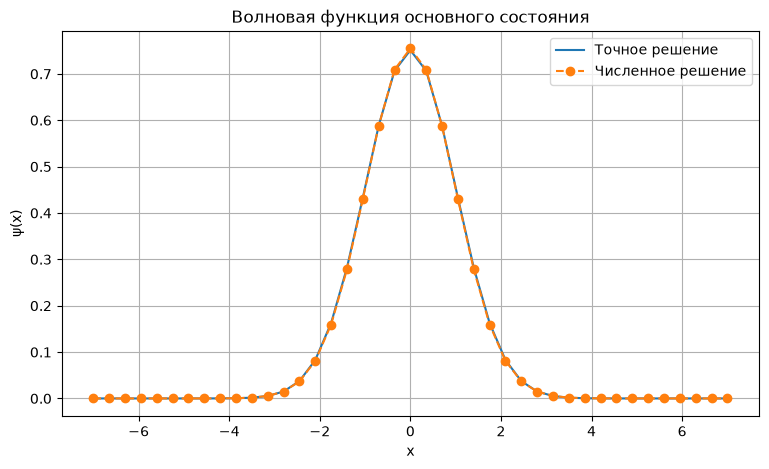

In [10]:

# Выбираем положительный знак волновой функции
if psi_inner[np.argmax(np.abs(psi_inner))] < 0:
    psi_inner = -psi_inner

# Нормируем на сетке
norm = np.sqrt(h * np.sum(psi_inner**2))
psi_inner = psi_inner / norm

# Добавляем нулевые значения на границах
psi_numeric = np.zeros(N + 1)
psi_numeric[1:-1] = psi_inner

# Точное решение
E_exact = 0.5

psi_exact = (
    np.pi**(-0.25) * np.exp(-x**2 / 2)
)

# Погрешности
error_E = abs(E0 - E_exact)
error_psi = np.max(np.abs(psi_numeric - psi_exact))

print("Ошибка энергии:", error_E)
print("Максимальная ошибка функции:", error_psi)
print("Нормировка:", h * np.sum(psi_numeric**2))

# График
plt.figure(figsize=(9, 5))

plt.plot(x, psi_exact, label="Точное решение")
plt.plot(x, psi_numeric, "o--", label="Численное решение")

plt.xlabel("x")
plt.ylabel("ψ(x)")
plt.title("Волновая функция основного состояния")
plt.grid()
plt.legend()
plt.show()
